In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["figure.dpi"] = 110

rng = np.random.default_rng(seed=0)


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


def relu(z):
    return np.maximum(0.0, z)


def bce_loss(y_pred, y_true):
    eps = 1e-12
    y_pred = np.clip(y_pred, eps, 1 - eps)
    return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))


def plot_decision_boundary(predict_fn, X, y, title="", ax=None):
    """Shade the plane by what predict_fn says, then scatter the real data on top."""
    if ax is None:
        _, ax = plt.subplots()
    pad = 0.5
    x_min, x_max = X[:, 0].min() - pad, X[:, 0].max() + pad
    y_min, y_max = X[:, 1].min() - pad, X[:, 1].max() + pad
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = predict_fn(grid).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=50, cmap="coolwarm", alpha=0.7)
    ax.contour(xx, yy, zz, levels=[0.5], colors="k", linewidths=2)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=35)
    ax.set_title(title)
    ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2")
    return ax


print("ready")

ready


---
# 4.1 A problem one neuron cannot solve

The classic example is **XOR**: four points, two classes. Output 1 when exactly one
input is 1, otherwise 0.

| x₁ | x₂ | label |
|---|---|---|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

Look at the plot below and try to draw a single straight line with the two red points
on one side and the two blue points on the other. You can't. There is no such line —
this isn't a matter of not looking hard enough.

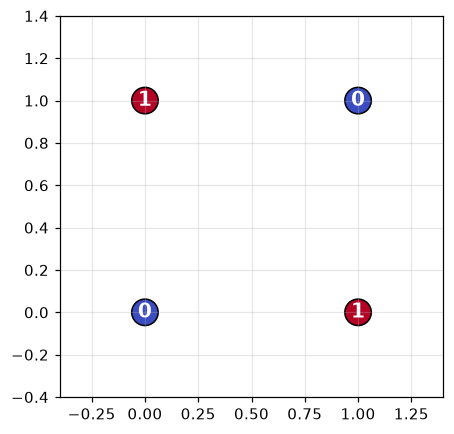

In [6]:
X_xor = np.array([[0.0, 0.0],
                 [0.0, 1.0],
                 [1.0, 0.0],
                 [1.0, 1.0]])
y_xor = np.array([0.0, 1.0, 1.0, 0.0])

plt.figure(figsize=(4.5, 4.5))
plt.scatter(X_xor[:, 0], X_xor[:, 1], c=y_xor, cmap="coolwarm",
            edgecolor="k", s=300)
for (x1, x2), label in zip(X_xor, y_xor):
    plt.annotate(f"{int(label)}", (x1, x2), fontsize=13, fontweight="bold",
                 ha="center", va="center", color="white")
plt.xlim(-0.4, 1.4)
plt.ylim(-0.4, 1.4)
plt.show()

X (400, 2)  y (400,)


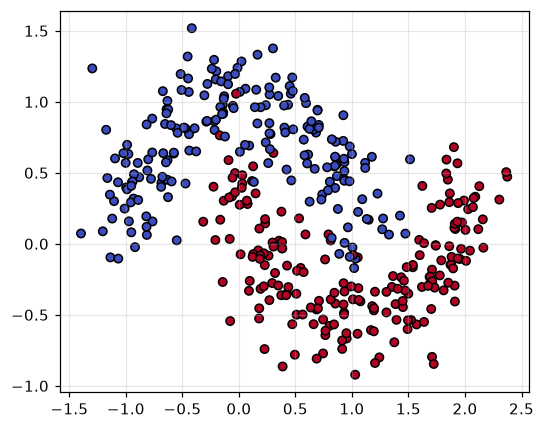

In [9]:
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=400, noise=0.20, random_state=3)
y = y.astype(float)

print("X", X.shape, " y", y.shape)

plt.figure(figsize=(5.5, 4.5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=30)
plt.show()

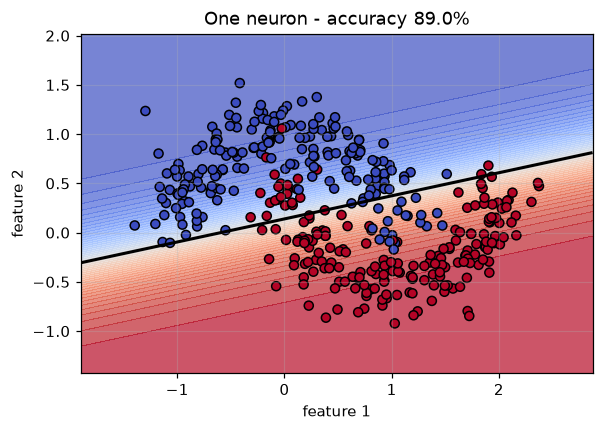

In [10]:
def train_neuron(X, y, learning_rate=0.5, n_steps=500):
    n_samples, n_features = X.shape
    r = np.random.default_rng(0)
    w = r.normal(size=n_features) * 0.01
    b = 0.0
    for _ in range(n_steps):
        y_pred = sigmoid(X @ w + b)
        error = y_pred - y
        w -= learning_rate * (X.T @ error) / n_samples
        b -= learning_rate * np.mean(error)
    return w, b

w1n, b1n = train_neuron(X, y)
acc = np.mean((sigmoid(X @ w1n + b1n) > 0.5) == y)

plot_decision_boundary(lambda g: sigmoid(g @ w1n + b1n), X, y,
                       title = f"One neuron - accuracy {acc:.1%}")
plt.show()

In [12]:
def init_params(n_input, n_hidden, seed=0):
    """Create the four parameter arrays."""
    r = np.random.default_rng(seed)
    return {
        "W1": r.normal(size=(n_input, n_hidden)) * np.sqrt(2.0 / n_input),
        "b1": np.zeros(n_hidden),
        "W2": r.normal(size=(n_hidden, 1)) * np.sqrt(2.0 / n_hidden),
        "b2": np.zeros(1),
    }

def forward(X, p):
    """Run the network."""
    Z1 = X @ p["W1"] + p["b1"]
    A1 = relu(Z1)
    Z2 = A1 @ p["W2"] + p["b2"]
    A2 = sigmoid(Z2)
    return A2, {"Z1": Z1, "A1": A1, "Z2": Z2, "A2": A2}

params = init_params(n_input=2, n_hidden=8)
for name, arr in params.items():
    print(f"{name}: shape {str(arr.shape):8}")

y_hat, cache = forward(X, params)
print()
print("predictions shape:", y_hat.shape)
print("first 3 (untrained, so near 0.5):", np.round(y_hat[:3, 0], 3))

W1: shape (2, 8)  
b1: shape (8,)    
W2: shape (8, 1)  
b2: shape (1,)    

predictions shape: (400, 1)
first 3 (untrained, so near 0.5): [0.571 0.54  0.553]


In [ ]:
def backward(X, Y, p, cache):
    n = X.shape[0]
    A1, Z1, A2 = cache["A1"], cache["Z1"], cache["A2"]

    # ---- output layer ----
    dZ2 = (A2 - Y) / n
    dW2 = A1.T @ dZ2
    db2 = dZ2.sum(axis=0)

    # ---- pass the blame back to the hidden layer ----
    dA1 = dZ2 @ p["W2"].T
    dZ1 = dA1 * (Z1 > 0)

    # ---- hidden layer ----
    dW1 = X.T @ dZ1
    db1 = dZ1.sum(axis=0)

    return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}

h
